# TITANIC DATASET - COMPLETE EDA PROJECT

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

### 1. LOAD DATASET

In [2]:
df = pd.read_csv(r"titanic.csv")

In [5]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'Siblings/Spouses Aboard', 'Parents/Children Aboard', 'Fare']


In [6]:
print("\nShape of Dataset:")
print(df.shape)


Shape of Dataset:
(887, 8)


In [7]:
print("\nData Types:")
print(df.dtypes)


Data Types:
Survived                     int64
Pclass                       int64
Name                        object
Sex                         object
Age                        float64
Siblings/Spouses Aboard      int64
Parents/Children Aboard      int64
Fare                       float64
dtype: object


In [8]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Survived                   0
Pclass                     0
Name                       0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64


In [9]:
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Duplicate Rows:
0


### 2. SUMMARY STATISTICS

In [10]:
print("\nSummary Statistics")
print(df.describe())


Summary Statistics
         Survived      Pclass         Age  Siblings/Spouses Aboard  \
count  887.000000  887.000000  887.000000               887.000000   
mean     0.385569    2.305524   29.471443                 0.525366   
std      0.487004    0.836662   14.121908                 1.104669   
min      0.000000    1.000000    0.420000                 0.000000   
25%      0.000000    2.000000   20.250000                 0.000000   
50%      0.000000    3.000000   28.000000                 0.000000   
75%      1.000000    3.000000   38.000000                 1.000000   
max      1.000000    3.000000   80.000000                 8.000000   

       Parents/Children Aboard       Fare  
count               887.000000  887.00000  
mean                  0.383315   32.30542  
std                   0.807466   49.78204  
min                   0.000000    0.00000  
25%                   0.000000    7.92500  
50%                   0.000000   14.45420  
75%                   0.000000   31.13750

In [11]:
print("\nCategorical Summary")
print(df.describe(include='object'))


Categorical Summary
                      Name   Sex
count                  887   887
unique                 887     2
top     Mr. Patrick Dooley  male
freq                     1   573


### 3. DATA CLEANING

In [12]:
# Remove duplicates if any
df = df.drop_duplicates()

In [13]:
# Check missing values again
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


Missing Values After Cleaning:
Survived                   0
Pclass                     0
Name                       0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64


### 4. FEATURE ENGINEERING

In [14]:
df['FamilySize'] = (
    df['Siblings/Spouses Aboard']
    + df['Parents/Children Aboard']
    + 1
)

df['IsAlone'] = np.where(df['FamilySize'] == 1, 1, 0)

print("\nNew Features Added:")
print(df[['FamilySize', 'IsAlone']].head())



New Features Added:
   FamilySize  IsAlone
0           2        0
1           2        0
2           1        1
3           2        0
4           1        1


### 5. DISTRIBUTION ANALYSIS

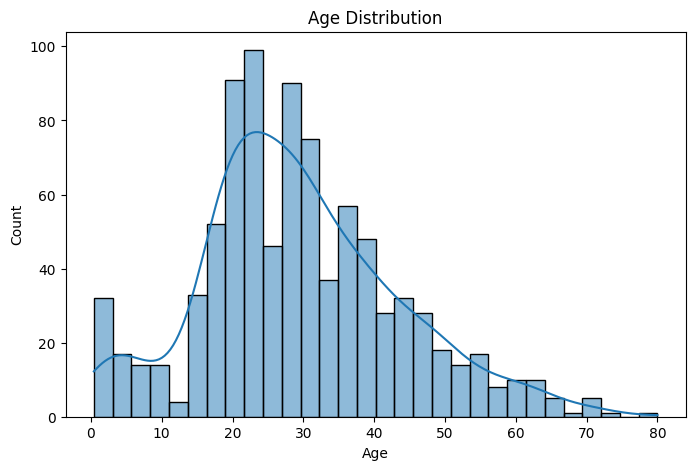

In [15]:
# Age Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['Age'], bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

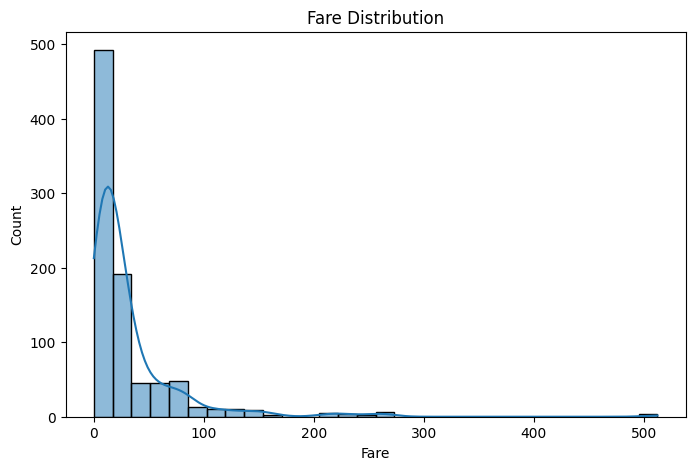

In [16]:
# Fare Distribution
plt.figure(figsize=(8,5))
sns.histplot(df['Fare'], bins=30, kde=True)
plt.title("Fare Distribution")
plt.show()

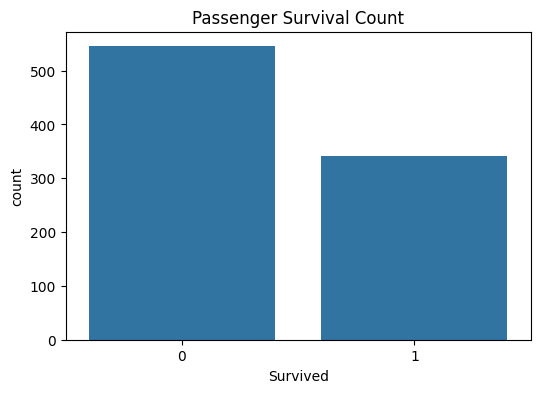

In [17]:
# Survival Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='Survived', data=df)
plt.title("Passenger Survival Count")
plt.show()

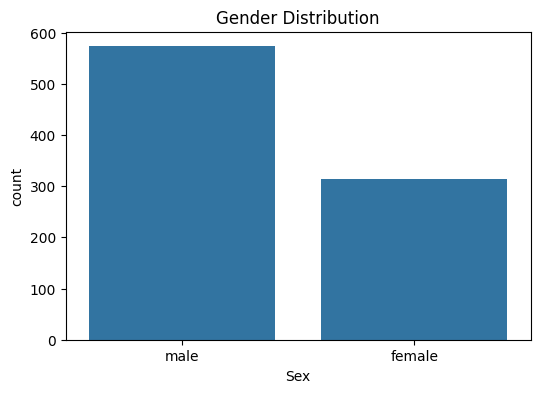

In [18]:
# Gender Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='Sex', data=df)
plt.title("Gender Distribution")
plt.show()


### 6. SURVIVAL ANALYSIS

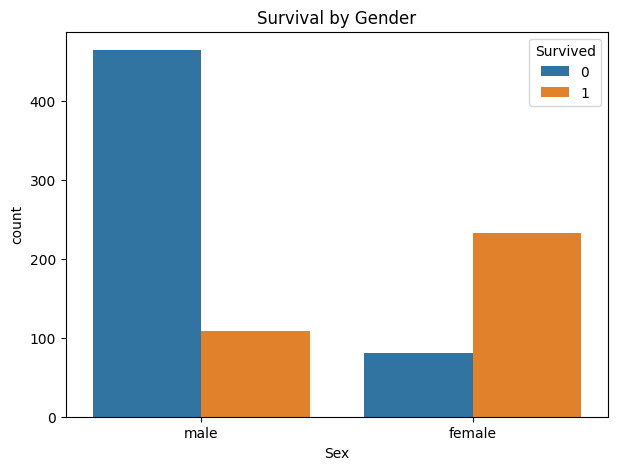

In [19]:
# Survival by Gender
plt.figure(figsize=(7,5))
sns.countplot(x='Sex', hue='Survived', data=df)
plt.title("Survival by Gender")
plt.show()

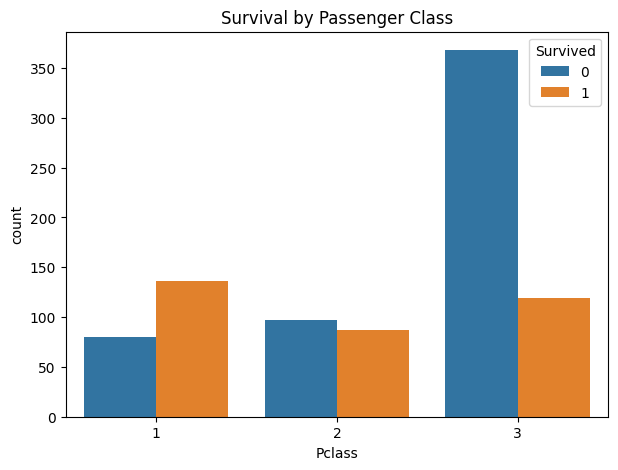

In [20]:
# Survival by Passenger Class
plt.figure(figsize=(7,5))
sns.countplot(x='Pclass', hue='Survived', data=df)
plt.title("Survival by Passenger Class")
plt.show()

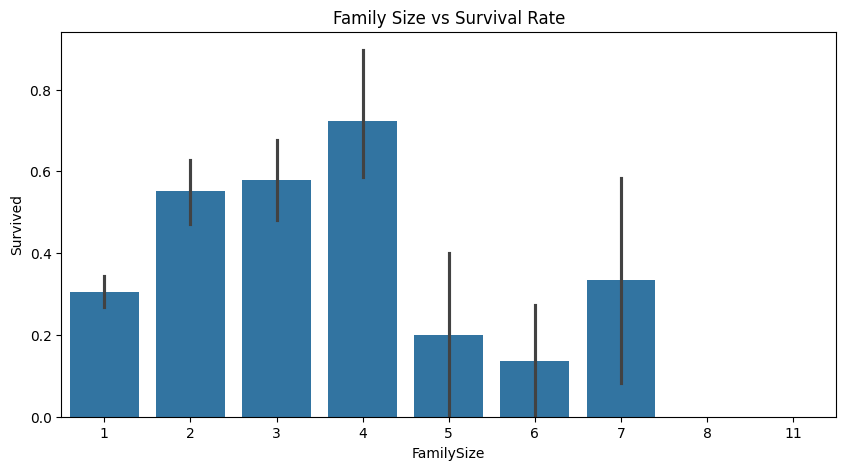

In [21]:
# Survival by Family Size
plt.figure(figsize=(10,5))
sns.barplot(x='FamilySize', y='Survived', data=df)
plt.title("Family Size vs Survival Rate")
plt.show()

### 7. CORRELATION ANALYSIS

In [22]:
numeric_df = df.select_dtypes(include=np.number)

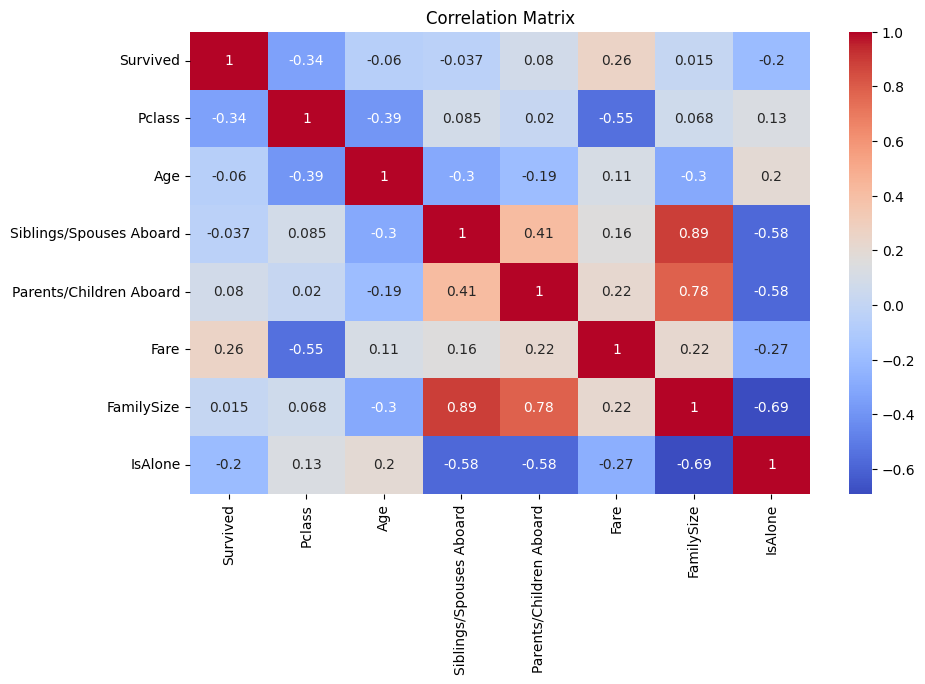

In [23]:
plt.figure(figsize=(10,6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title("Correlation Matrix")
plt.show()

In [24]:
# Survival Rate by Class
print("\nSurvival Percentage by Class")
print(
    pd.crosstab(
        df['Pclass'],
        df['Survived'],
        normalize='index'
    ) * 100
)


Survival Percentage by Class
Survived          0          1
Pclass                        
1         37.037037  62.962963
2         52.717391  47.282609
3         75.564682  24.435318


In [25]:
# Survival Rate by Gender
print("\nSurvival Percentage by Gender")
print(
    pd.crosstab(
        df['Sex'],
        df['Survived'],
        normalize='index'
    ) * 100
)


Survival Percentage by Gender
Survived          0          1
Sex                           
female    25.796178  74.203822
male      80.977312  19.022688


### 8. OUTLIER DETECTION

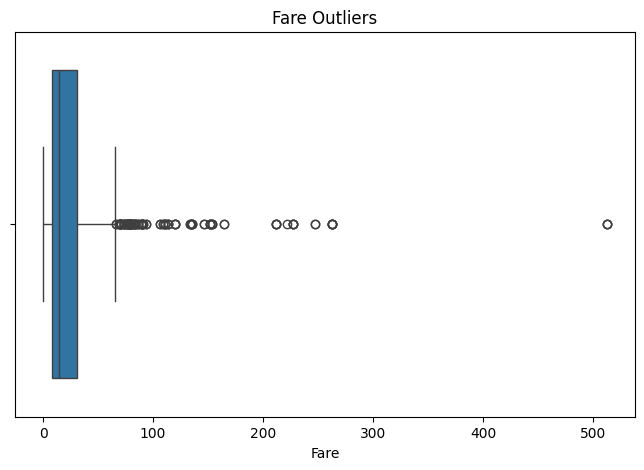

In [26]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Fare'])
plt.title("Fare Outliers")
plt.show()

In [27]:
# Z-score method
z_scores = np.abs(stats.zscore(df['Fare']))
outliers = df[z_scores > 3]

In [28]:
print("\nNumber of Fare Outliers:")
print(len(outliers))



Number of Fare Outliers:
20


In [29]:
print("\nTop Outlier Records:")
print(outliers[['Name', 'Fare']].head())


Top Outlier Records:
                                               Name      Fare
27                    Mr. Charles Alexander Fortune  263.0000
87                        Miss. Mabel Helen Fortune  263.0000
117                         Mr. Quigg Edmond Baxter  247.5208
257                                 Miss. Anna Ward  512.3292
297  Mrs. James (Helene DeLaudeniere Chaput) Baxter  247.5208


### 9. ADVANCED VISUALIZATIONS


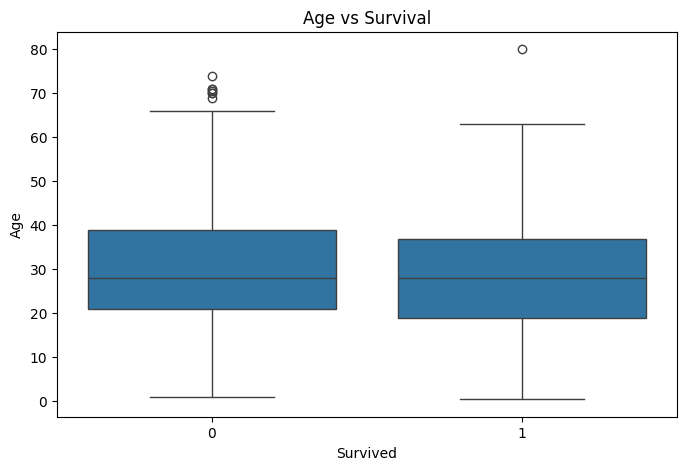

In [30]:
# Age Distribution by Survival
plt.figure(figsize=(8,5))
sns.boxplot(
    x='Survived',
    y='Age',
    data=df
)
plt.title("Age vs Survival")
plt.show()

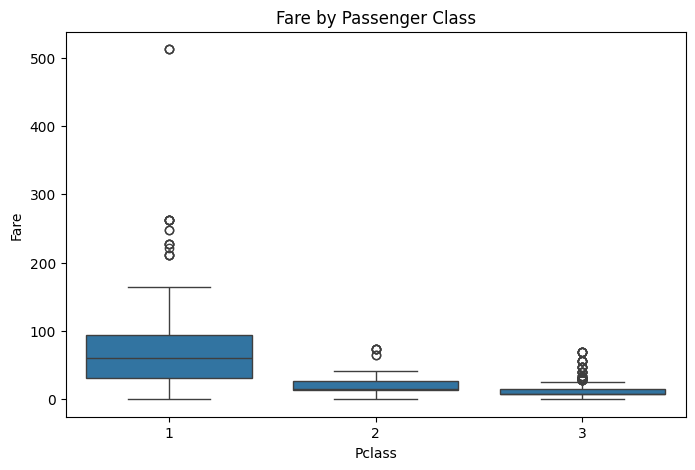

In [31]:
# Fare Distribution by Class
plt.figure(figsize=(8,5))
sns.boxplot(
    x='Pclass',
    y='Fare',
    data=df
)
plt.title("Fare by Passenger Class")
plt.show()


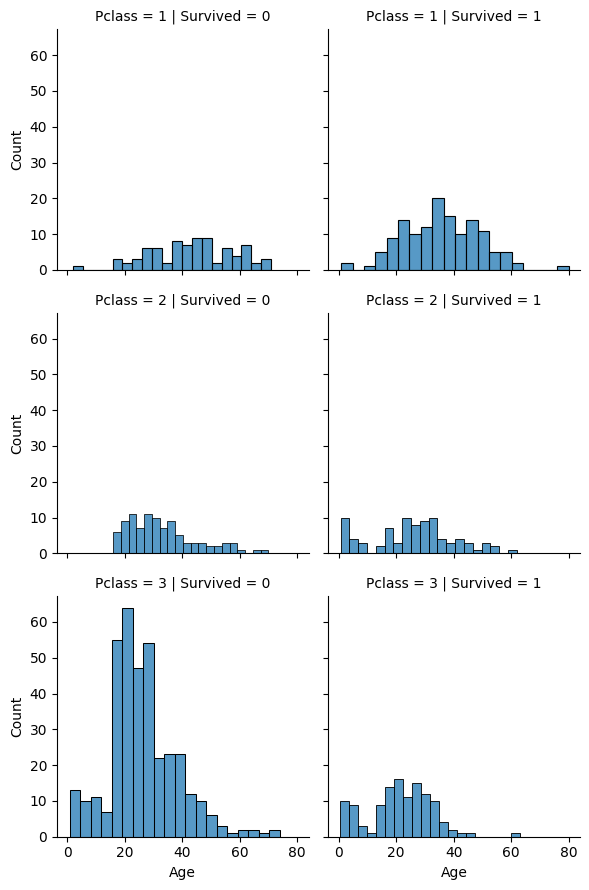

In [32]:
# Facet Grid
g = sns.FacetGrid(
    df,
    col='Survived',
    row='Pclass',
    height=3
)

g.map(
    sns.histplot,
    'Age',
    bins=20
)

plt.show()

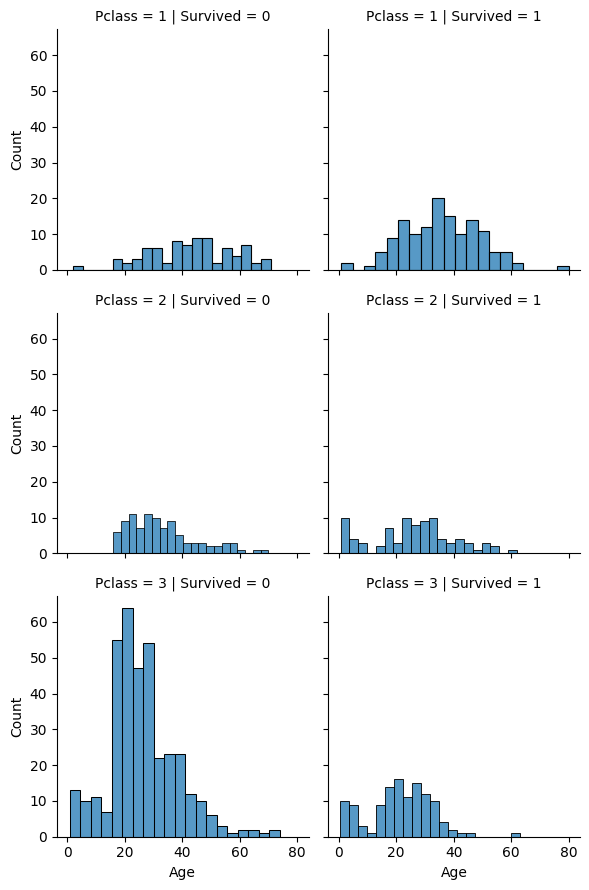

In [33]:
# Facet Grid
g = sns.FacetGrid(
    df,
    col='Survived',
    row='Pclass',
    height=3
)

g.map(
    sns.histplot,
    'Age',
    bins=20
)

plt.show()

### 10. STATISTICAL ANALYSIS

In [34]:
print("\nSkewness")


Skewness


In [35]:
print("Age:", df['Age'].skew())
print("Fare:", df['Fare'].skew())

Age: 0.44718857190799916
Fare: 4.777671399019824


In [36]:
print("\nKurtosis")


Kurtosis


In [37]:
print("Age:", df['Age'].kurt())
print("Fare:", df['Fare'].kurt())

Age: 0.2925590867837582
Fare: 33.26460490128922


In [38]:
# Pearson Correlation
print("\nPearson Correlation")


Pearson Correlation


In [39]:
print(
    df[
        [
            'Age',
            'Fare',
            'FamilySize',
            'Survived'
        ]
    ].corr(method='pearson')
)

                 Age      Fare  FamilySize  Survived
Age         1.000000  0.112329   -0.300297 -0.059665
Fare        0.112329  1.000000    0.216250  0.256179
FamilySize -0.300297  0.216250    1.000000  0.014673
Survived   -0.059665  0.256179    0.014673  1.000000


In [40]:
# Spearman Correlation
print("\nSpearman Correlation")


Spearman Correlation


In [41]:
print(
    df[
        [
            'Age',
            'Fare',
            'FamilySize',
            'Survived'
        ]
    ].corr(method='spearman')
)


                 Age      Fare  FamilySize  Survived
Age         1.000000  0.156062   -0.228815 -0.030265
Fare        0.156062  1.000000    0.527745  0.322264
FamilySize -0.228815  0.527745    1.000000  0.162942
Survived   -0.030265  0.322264    0.162942  1.000000


### 11. HYPOTHESIS TESTING

In [42]:
print("\nHYPOTHESIS 1")
print("Higher Class -> Better Survival")


HYPOTHESIS 1
Higher Class -> Better Survival


In [43]:
print(
    pd.crosstab(
        df['Pclass'],
        df['Survived'],
        normalize='index'
    ) * 100
)

Survived          0          1
Pclass                        
1         37.037037  62.962963
2         52.717391  47.282609
3         75.564682  24.435318


In [44]:
print("\nHYPOTHESIS 2")
print("Female Passengers Survived More")


HYPOTHESIS 2
Female Passengers Survived More


In [45]:
print(
    pd.crosstab(
        df['Sex'],
        df['Survived'],
        normalize='index'
    ) * 100
)


Survived          0          1
Sex                           
female    25.796178  74.203822
male      80.977312  19.022688


In [46]:
print("\nHYPOTHESIS 3")
print("Higher Fare -> Better Survival")


HYPOTHESIS 3
Higher Fare -> Better Survival


In [47]:
print(
    df.groupby('Survived')['Fare'].mean()
)


Survived
0    22.208584
1    48.395408
Name: Fare, dtype: float64


### 12. FINAL REPORT SUMMARY

In [48]:
print("\nEDA COMPLETED SUCCESSFULLY")
print("Key Areas Covered:")
print("✔ Dataset Overview")
print("✔ Data Cleaning")
print("✔ Summary Statistics")
print("✔ Distribution Analysis")
print("✔ Correlation Analysis")
print("✔ Outlier Detection")
print("✔ Advanced Visualizations")
print("✔ Feature Engineering")
print("✔ Hypothesis Testing")
print("✔ Recommendations Ready")


EDA COMPLETED SUCCESSFULLY
Key Areas Covered:
✔ Dataset Overview
✔ Data Cleaning
✔ Summary Statistics
✔ Distribution Analysis
✔ Correlation Analysis
✔ Outlier Detection
✔ Advanced Visualizations
✔ Feature Engineering
✔ Hypothesis Testing
✔ Recommendations Ready
